# Wykład 7 — Gdy jedna zmienna nie wystarcza: tablice i praca z danymi

W W5 powtarzaliśmy instrukcje w pętlach, a w W6 poznaliśmy adresy i wskaźniki. Teraz połączymy te umiejętności: zamiast jednej liczby przetworzymy całą kolekcję pomiarów. Na końcu przejdziemy drogę **plik → tablica → obliczenia → sortowanie → plik**.

**Cel:** umieć wyjaśnić, gdzie znajduje się każdy element, które indeksy są poprawne i jaką część tablicy wolno przekazać funkcji. Nauczymy się również przygotowywać powtarzalne dane i sprawdzać, czy operacje na pliku się powiodły.

**Jak pracować:** przed doświadczeniem zapisz przewidywany wynik. Uruchom program, porównaj wynik z przewidywaniem i zmień jeden szczegół. Każdy program będzie kompletny: własne nagłówki i własne `main`. Korzystamy z C11 i kernela C; doświadczenia nie wymagają wpisywania danych z klawiatury.

Zachowujemy rozróżnienie z W6: obiekt, jego wartość, adres i prowadzący do niego wskaźnik to różne rzeczy. Rozmiary sprawdzamy przez `sizeof`; typowe 4 B dla `int` i 8 B dla wskaźnika odnoszą się do demonstracyjnego Linux/x86-64 z GCC. Konkretne adresy mogą zmieniać się między uruchomieniami.

## W7.1 — Po co nam tablice?

**Problem:** mamy sto pomiarów temperatury. Czy potrzebujemy nazw `pomiar1`, `pomiar2`, …, `pomiar100`? A jak zapisać pętlę, która obliczy ich sumę?

Tablica grupuje elementy tego samego typu pod jedną nazwą. Numer elementu, czyli **indeks**, pozwala wybrać konkretny pomiar. Deklaracja `int tab[5]` rezerwuje pięć elementów typu `int`; ich indeksy to `0`, `1`, `2`, `3`, `4`. Pojemność nie jest ostatnim indeksem — numerowanie zaczynamy od zera.

**Przewidź:** ile elementów mieści `int tab[5]` i jaki indeks ma ostatni? W doświadczeniu nadamy elementom wartości przy deklaracji, odczytamy wybrany element i zmienimy jeden pomiar. Tablica oszczędza wymyślania nazw, ale nadal trzeba ustalić wartość każdego odczytywanego elementu.

### Pięć miejsc, pięć indeksów

Zapis `{3, 9, 5}` przy deklaracji nadaje wartości pierwszym trzem elementom. Pozostałe elementy tej tablicy zostają zainicjalizowane zerami. To co innego niż lokalne `int tab[5];` bez inicjalizacji: jego elementów nie wolno odczytywać, zanim nadamy im wartości.

**Przewidź:** zapisz pięć liczb pierwszego wydruku, a następnie wartość elementu o indeksie 1 po przypisaniu. Który to pomiar: pierwszy czy drugi?

In [ ]:
#include <stdio.h>

int main(void)
{
    int tab[5] = {3, 9, 5};

    printf("Start: %d %d %d %d %d\n",
           tab[0], tab[1], tab[2], tab[3], tab[4]);
    tab[1] = 7;
    printf("Drugi pomiar: %d\n", tab[1]);
    printf("Pierwszy i ostatni: %d %d\n", tab[0], tab[4]);
    return 0;
}

**Interpretacja:** na początku mamy `3 9 5 0 0`, potem drugi pomiar wynosi 7. Przypisanie `tab[1] = 7` zmienia jeden element. Pojemność nadal wynosi 5; ostatni indeks to 4. Każdy element jest osobnym obiektem `int` wewnątrz tablicy.

**Zmień:** zastąp `tab[1] = 7` przez `tab[4] = -2` i dopasuj opis drugiego wydruku. Przewidź zmianę ostatniego pomiaru. Następnie wypróbuj inicjalizację `{0}`: wszystkie pięć elementów będzie miało wartość zero.

**Kontrola:** dlaczego `tab[5]` nie jest piątym elementem? Piąty ma indeks 4, a indeks 5 wychodzi poza tablicę. Nie dopisuj odczytu ani zapisu `tab[5]` do działającego programu.

W tym wykładzie wybieramy **tablice o stałym rozmiarze**, np. `int tab[5]` lub `double pomiary[50]`. Nie oznacza to użycia słowa kluczowego `static`. C zna także tablice o zmiennej długości (VLA), np. rozmiar zależny od `n`; ich obsługa zależy od wersji i implementacji języka. Tutaj świadomie ich nie używamy: stała pojemność pozwoli jasno kontrolować granice.

Inicjalizację z klamrami zapisujemy przy deklaracji. Późniejsze `tab = ...` nie służy w C do przypisywania całej tablicy; na razie zmieniamy jej poszczególne elementy.

## W7.2 — Tablica w pamięci

**Problem:** co oznacza „następny element”, gdy patrzymy na pamięć programu?

Elementy tablicy leżą kolejno, bez przerw pomiędzy elementami. Cała tablica zajmuje liczbę elementów pomnożoną przez rozmiar pojedynczego elementu. Z W6 znamy `sizeof` oraz adres uzyskany przez `&`. Teraz porównamy adresy `&tab[0]`, `&tab[1]` i `&tab[2]` w obrębie jednego rzeczywistego obiektu tablicowego.

**Przewidź:** jeśli `int` zajmuje 4 B, ile bajtów zajmuje `int tab[3]`? Czy przejście do następnego elementu oznacza krok o jeden bajt? Doświadczenie i rysunek z podziałką bajtową pozwolą porównać rozmiar elementu, rozmiar całej tablicy oraz indeks. Umowne adresy na rysunku opisują relacje, a nie adresy wymagane w Twoim uruchomieniu.

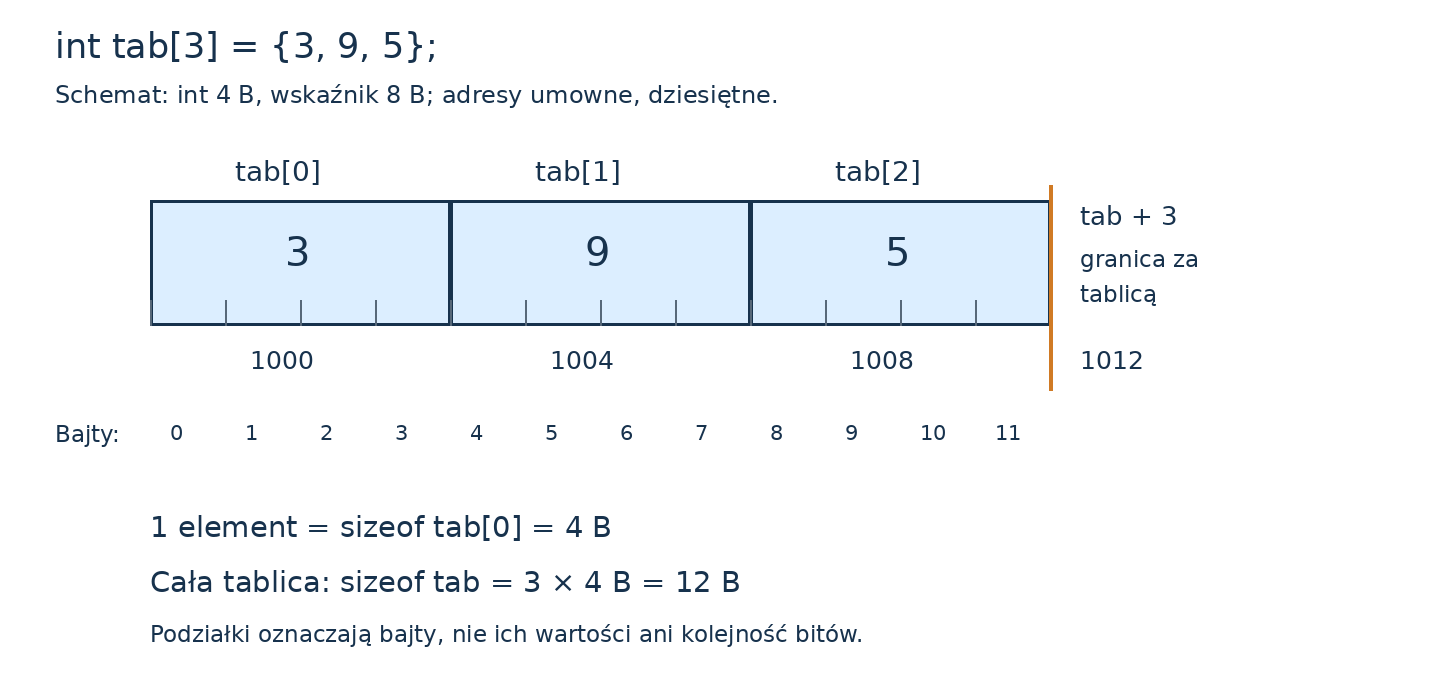

Trzy elementy tablicy i dwanaście bajtów na demonstracyjnej platformie. Adresy są umowne; granica za tablicą nie jest czwartym elementem.

### Rozmiar całości i rozmiar elementu

**Przewidź:** oblicz `sizeof tab / sizeof tab[0]`. Czy ten iloraz zależy od tego, czy `int` zajmuje 4 B, czy inną liczbę bajtów? Następnie uruchom program i porównaj pary adresów, bez zgadywania ich konkretnych wartości. Wynik `sizeof` wypisujemy przez `%zu`, a adres przez `%p` z argumentem `(void *)`.

In [ ]:
#include <stdio.h>

int main(void)
{
    int tab[3] = {3, 9, 5};

    printf("Cala tablica: %zu B\n", sizeof tab);
    printf("Jeden element: %zu B\n", sizeof tab[0]);
    printf("Liczba elementow: %zu\n", sizeof tab / sizeof tab[0]);
    printf("&tab[0]=%p, tab=%p\n", (void *)&tab[0], (void *)tab);
    printf("&tab[1]=%p, tab+1=%p\n", (void *)&tab[1], (void *)(tab + 1));
    printf("&tab[2]=%p, tab+2=%p\n", (void *)&tab[2], (void *)(tab + 2));
    printf("Jeden za tablica: %p\n", (void *)(tab + 3));
    return 0;
}

**Interpretacja:** liczba elementów wynosi 3, niezależnie od rozmiaru `int`. Na naszej platformie rozmiary to 12 B i 4 B. W każdej parze widzimy równy adres; przejście od elementu do następnego odpowiada `sizeof tab[0]` bajtom. Nie ma przerw pomiędzy elementami.

Z W6 znamy wskaźnik jeden za obiektem. Tutaj `tab + 3` wskazuje granicę za trzema elementami. Wolno go utworzyć i wypisać, ale nie odczytywać `*(tab + 3)`. Poprawne odczyty kończą się na indeksie 2.

**Zmień:** dodaj czwartą wartość w deklaracji: `int tab[4] = {3, 9, 5, 2};`. Przewidź nowy rozmiar całości i iloraz rozmiarów. W ostatnim wydruku zmień granicę na `tab + 4`. Pary dla pierwszych trzech elementów nadal opisują tę samą relację.

**Kontrola:** przy hipotetycznym `sizeof(int) == 2` ile bajtów zajmowałaby tablica trzech `int`? Sześć, a iloraz rozmiarów nadal dałby 3. Czy diagram pokazuje zapis bitowy liczby 9? Nie: opisuje położenie i rozmiar obiektów, bez interpretowania ich poszczególnych bajtów.

## W7.3 — Czy tablica jest wskaźnikiem?

**Problem:** dlaczego można napisać `int *p = tab`, skoro zadeklarowaliśmy tablicę?

**Tablica nie jest wskaźnikiem.** W wielu wyrażeniach nazwa tablicy przekształca się we wskaźnik do jej pierwszego elementu. Wskaźnik `p` jest osobnym obiektem przechowującym adres; sama tablica przechowuje elementy. Dzięki temu `tab[i]`, `*(tab + i)` i `p[i]` mogą docierać do tego samego elementu, gdy `p` wskazuje początek tablicy i indeks jest poprawny.

**Przewidź:** czy `sizeof tab` i `sizeof p` muszą być równe? Porównamy oba rozmiary i trzy drogi odczytu. Przyjrzymy się też wyjątkom od przekształcenia: `sizeof tab` dotyczy całej tablicy, a `&tab` jest adresem całej tablicy, o innym typie niż `&tab[0]`. Ten sam początek pamięci nie oznacza tego samego typu ani tego samego kroku arytmetyki.

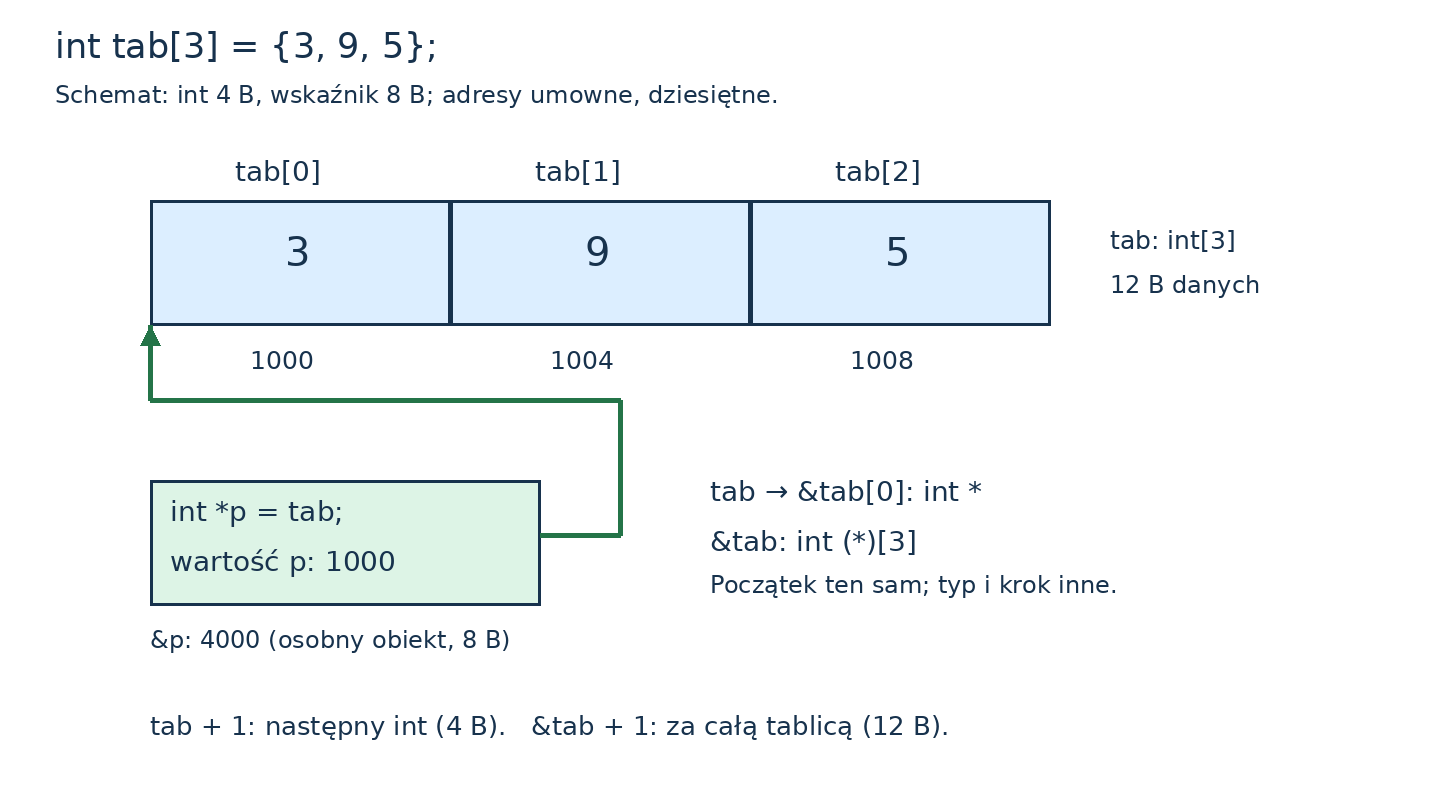

Tablica zawiera liczby, a osobny obiekt p przechowuje adres jej pierwszego elementu. Podane rozmiary i adresy służą ilustracji.

### Trzy drogi do tego samego elementu

**Przewidź:** dla `i = 2` porównaj `tab[i]`, `*(tab + i)` i `p[i]`. Co zmieni zapis `p[1] = 7`? Który obiekt opisuje `sizeof p`, a który `sizeof tab`?

Operator indeksowania działa przez arytmetykę wskaźnika: `p[i]` oznacza `*(p + i)`. Ten zapis jest poprawny tylko dla odpowiedniego wskaźnika i indeksu. Sama składnia nawiasów nie kontroluje granic.

In [ ]:
#include <stdio.h>

int main(void)
{
    int tab[3] = {3, 9, 5};
    int *p = tab;
    int i = 2;

    printf("Trzy odczyty: %d %d %d\n", tab[i], *(tab + i), p[i]);
    printf("p == &tab[0]: %d\n", p == &tab[0]);
    printf("sizeof tab=%zu B, sizeof p=%zu B\n", sizeof tab, sizeof p);
    printf("Adres osobnego wskaznika &p=%p\n", (void *)&p);
    p[1] = 7;
    printf("Po p[1]=7: %d %d %d\n", tab[0], tab[1], tab[2]);
    printf("tab+1=%p, &tab+1=%p\n",
           (void *)(tab + 1), (void *)(&tab + 1));
    p = tab + 1;
    printf("Po przesunieciu p: p[0]=%d, tab[1]=%d\n", p[0], tab[1]);
    return 0;
}

**Interpretacja:** pierwsze trzy odczyty dają `5 5 5`, a porównanie adresów daje 1. Zapis przez `p[1]` zmienia oryginalne dane na `3 7 5`. Na naszej platformie `sizeof tab` wynosi 12 B, a `sizeof p` 8 B. Równość tych dwóch rozmiarów na innej platformie również nie uczyniłaby tablicy wskaźnikiem.

W ostatnich dwóch instrukcjach zmieniamy sam wskaźnik: po `p = tab + 1` jego `p[0]` oznacza drugi element tablicy, czyli 7. Tablica nadal ma te same trzy elementy. `p` można przepiąć; nazwy tablicy nie można przypisaniem „przesunąć”.

| Wyrażenie | Co opisuje? | Krok po dodaniu 1 |
|:--|:--|:--|
| `tab` w większości wyrażeń | Po przekształceniu: wskaźnik do pierwszego `int` | Jeden `int` |
| `&tab[0]` | Wskaźnik do pierwszego `int`, typ `int *` | Jeden `int` |
| `&tab` | Wskaźnik do całej tablicy, typ `int (*)[3]` | Całą tablicę trzech `int` |
| `&p` | Adres osobnego obiektu wskaźnika | Nie używamy tutaj jego arytmetyki |

`sizeof tab` i `&tab` nie wykonują zwykłego przekształcenia tablicy we wskaźnik do pierwszego elementu. Nie musisz teraz pisać deklaracji wskaźnika do całej tablicy; wystarczy rozpoznać, do jakiego obiektu prowadzi. `&tab + 1` wskazuje za całą tablicę i nie wolno go dereferencjonować.

**Zmień:** ustaw początkowe `i = 0`, a zapis zmieniający drugi element zastąp `p[1] = -4`. Przewidź trzy pierwsze odczyty oraz końcowe `p[0]`. Po uruchomieniu powinny wynieść odpowiednio `3 3 3` i −4.

**Kontrola:** czy po końcowym `p = tab + 1` wolno użyć `p[2]`? Nie: oznaczałoby element za końcem tej tablicy. Wskaźnik nie pamięta dostępnej długości; po zmianie początku musimy odpowiednio ograniczyć indeksy.

**Ciekawostka do przeczytania:** `2[tab]` jest dozwolonym, lecz nieczytelnym sposobem zapisania `*(2 + tab)`, a więc `tab[2]`. Nie stosuj go w swoich programach — kod ma pomagać czytającemu, a nie sprawdzać jego refleks.

## W7.4 — Tablice i pętle

**Problem:** jak policzyć średnią pomiarów bez pięciu niemal identycznych instrukcji?

Licznik pętli będzie indeksem. Dla `n` używanych elementów przechodzimy po indeksach `0..n-1`, zapisując warunek `i < n`. Rozróżniamy **pojemność** tablicy i **liczbę używanych elementów**: można zarezerwować więcej miejsca, niż aktualnie potrzebujemy.

**Przewidź:** ile odczytów wykona pętla dla `n = 0`, `1` i `5`? Najpierw wypełnimy tablicę, potem obliczymy sumę, średnią, minimum i maksimum. Dla pustego zestawu suma może wynosić zero, lecz średnia i skrajne wartości wymagają osobnej decyzji. Błędny indeks oznacza niezdefiniowane zachowanie — język nie obiecuje ani awarii, ani sensownego wyniku. Takie błędy będziemy rozpoznawać w tekście, bez ich wykonywania.

### Pętla odwiedza elementy

`MAX_SIZE` będzie stałą pojemnością, a `n` liczbą aktualnie używanych elementów. Najpierw sprawdzamy `0 <= n && n <= MAX_SIZE`. Dopiero potem wypełniamy pierwsze `n` miejsc i je odczytujemy. Pozostałe miejsca nie zawierają jeszcze naszych danych — nie trzeba ich czytać tylko dlatego, że są dostępne.

**Przewidź:** wypisz pary indeks–wartość dla `n = 5`. Dlaczego obie pętle używają tego samego warunku `i < n`? Przy `n = MAX_SIZE` ostatni indeks nadal wynosi `MAX_SIZE - 1`.

In [ ]:
#include <stdio.h>
#define MAX_SIZE 8

int main(void)
{
    int tab[MAX_SIZE];
    int n = 5;

    if (n < 0 || n > MAX_SIZE) {
        puts("Niepoprawna liczba elementow.");
        return 1;
    }
    for (int i = 0; i < n; ++i) {
        tab[i] = 2 * (i + 1);
    }
    for (int i = 0; i < n; ++i) {
        printf("tab[%d]=%d\n", i, tab[i]);
    }
    printf("Pojemnosc=%d, uzywamy=%d\n", MAX_SIZE, n);
    return 0;
}

**Interpretacja:** indeksy `0..4` mają wartości `2, 4, 6, 8, 10`. Mamy osiem miejsc, ale używamy pięciu. Przed każdym odczytem odpowiedni element został zapisany przez pierwszą pętlę. Prosty niezmiennik z W5: przed obiegiem o indeksie `i` wypełnione są już miejsca o indeksach mniejszych od `i`.

**Zmień:** ustaw kolejno `n = 1`, `n = 0` i `n = MAX_SIZE`. Przewidź liczbę wierszy z elementami: 1, 0 i 8. Pojemność pozostanie równa 8. Następnie ustaw `n = 9`: program powinien zakończyć się komunikatem przed pierwszym zapisem.

**Kontrola:** znajdź błąd w samym nagłówku `for (int i = 0; i <= n; ++i)` użytym do odczytu. Dla `n = 5` odczytałby także niewypełnione miejsce `tab[5]`; dla `n = MAX_SIZE` wyszedłby poza tablicę. Nie uruchamiaj takiej wersji. To dwa różne powody, dla których poprawna pojemność sama nie wystarcza.

### Jedna tablica, kilka odpowiedzi

**Przewidź:** dla danych `3, 9, 5, -1, 4` policz ręcznie sumę, średnią, minimum i maksimum. Suma zaczyna od zera. Minimum i maksimum zaczniemy od pierwszego rzeczywistego pomiaru — nie od zera, które mogłoby wcale nie występować w danych.

Poniżej `n` może wybrać początkową część pięcioelementowej tablicy. Dane są małe i skończone, a ich suma mieści się w `double`. Nie traktujemy prostej sumy jako algorytmu odpornego na dowolne zakresy i błędy zaokrągleń.

In [ ]:
#include <stdio.h>

int main(void)
{
    double tab[5] = {3.0, 9.0, 5.0, -1.0, 4.0};
    int n = 5;
    int capacity = (int)(sizeof tab / sizeof tab[0]);
    double sum = 0.0;

    if (n < 0 || n > capacity) {
        puts("Niepoprawna liczba elementow.");
        return 1;
    }
    for (int i = 0; i < n; ++i) {
        sum += tab[i];
    }
    printf("Suma=%.2f\n", sum);
    if (n == 0) {
        puts("Brak pomiarow: srednia, minimum i maksimum nie sa okreslone.");
        return 0;
    }

    double minimum = tab[0];
    double maximum = tab[0];
    for (int i = 1; i < n; ++i) {
        if (tab[i] < minimum) minimum = tab[i];
        if (tab[i] > maximum) maximum = tab[i];
    }
    printf("Srednia=%.2f, min=%.2f, max=%.2f\n",
           sum / n, minimum, maximum);
    return 0;
}

**Interpretacja:** suma wynosi 20, średnia 4, minimum −1, a maksimum 9. Zaczynamy szukanie skrajnych wartości od `tab[0]`, więc pętla porównująca pozostałe elementy zaczyna od indeksu 1. Rzutowanie liczby elementów na `int` jest tutaj bezpieczne: pojemność to zaledwie 5.

**Zmień:** ustaw `n = 1`. Suma, średnia, minimum i maksimum powinny wynosić 3. Dla `n = 0` suma wyniesie zero, lecz program nie odczyta `tab[0]` ani nie podzieli przez zero. Następnie ustaw wszystkie pięć wartości na −2: minimum i maksimum powinny wynieść −2.

**Kontrola:** dlaczego `double maximum = 0.0` dałoby błędny wynik dla samych liczb ujemnych? Zero nie jest wtedy żadnym z pomiarów. Z kolei pusta suma równa zero nie dostarcza pierwszego pomiaru potrzebnego do zainicjalizowania minimum i maksimum.

## W7.5 — Tablica jako argument funkcji

**Problem:** jak wydzielić wypełnianie i obliczenia do funkcji, skoro tablica ma wiele elementów?

Przekażemy funkcji początek danych i ich długość: `fill(double a[], int n)`. W parametrze funkcji zapis tablicowy jest dostosowywany do typu wskaźnikowego. Funkcja nie otrzymuje kopii wszystkich elementów ani informacji o pojemności całej tablicy. Wywołujący musi zapewnić, że `n` mieści się w dostępnym obszarze.

Z W6 pamiętamy kopiowanie wartości adresu: funkcja może przez tę kopię zmieniać oryginalne elementy. Parametr `const double *a` pozwoli natomiast wyrazić zamiar samego odczytu, np. w `print` i `average`.

**Przewidź:** czy po `fill(tab, n)` zmienią się elementy `tab` w `main`? Doświadczenie połączy wypełnianie, wydruk i średnią. Sprawdzimy także, dlaczego liczbę elementów ustalamy przy rzeczywistej tablicy, a nie przez dzielenie rozmiarów wewnątrz funkcji.

### Początek danych i długość to dwa argumenty

Podzielmy poprzednie zadanie na operacje:

- `fill(double a[], int n)` zapisuje pierwsze `n` elementów;
- `print(const double *a, int n)` odczytuje i wypisuje elementy;
- `average(const double *a, int n, double *result)` oblicza średnią, a powodzenie zgłasza wartością 1. Przy `n <= 0` zwraca 0 i nie zmienia `*result`.

W `fill` zapis `double a[]` jako parametr oznacza wskaźnik `double *a`. To reguła deklaracji parametru funkcji, a nie deklaracja nowej tablicy o nieznanym rozmiarze. Wszystkie argumenty nadal są przekazywane przez wartość. Parametr `a` dostaje kopię adresu, przez którą dociera do oryginalnych elementów.

**Kontrakt:** dla `fill` i `print` wymagamy `n >= 0`; gdy `n > 0`, `a` ma wskazywać co najmniej `n` dostępnych elementów odpowiednio do zapisu albo odczytu. Dla średniej wymagamy zainicjalizowanych, skończonych danych o reprezentowalnej sumie i osobnego dostępnego obiektu `double` na wynik. Odrzucenie `n <= 0` następuje przed odczytem elementów lub zapisem wyniku. Wywołujący sprawdza pojemność — funkcja znająca tylko adres i długość nie potrafi jej odgadnąć.

`const double *a` zabrania zmieniać element przez ten parametr. Nie zamraża tablicy na zawsze: inna funkcja, np. `fill`, nadal może otrzymać do niej dostęp do zapisu.

**Przewidź:** czy po `fill` program wypisze zera, czy liczby `2, 4, 6, 8, 10`? Jaką średnią otrzyma? Czy rozmiar parametru `a` wypisany w `print` będzie równy rozmiarowi całej tablicy?

In [ ]:
#include <stdio.h>
#define MAX_SIZE 8

void fill(double a[], int n);
void print(const double *a, int n);
int average(const double *a, int n, double *result);

int main(void)
{
    double tab[MAX_SIZE];
    int n = 5;
    double mean = 0.0;

    if (n < 0 || n > MAX_SIZE) {
        puts("Niepoprawna liczba elementow.");
        return 1;
    }
    printf("Tablica w main: %zu B, pojemnosc=%zu\n",
           sizeof tab, sizeof tab / sizeof tab[0]);
    fill(tab, n);
    print(tab, n);
    if (average(tab, n, &mean)) {
        printf("Srednia=%.2f\n", mean);
    } else {
        puts("Brak sredniej dla pustego zestawu.");
    }
    return 0;
}

void fill(double a[], int n)
{
    for (int i = 0; i < n; ++i) {
        a[i] = 2.0 * (i + 1);
    }
}

void print(const double *a, int n)
{
    printf("Rozmiar parametru wskaznikowego: %zu B\n", sizeof a);
    for (int i = 0; i < n; ++i) {
        printf("%.1f ", a[i]);
    }
    puts("");
}

int average(const double *a, int n, double *result)
{
    if (n <= 0) return 0;
    double sum = 0.0;
    for (int i = 0; i < n; ++i) {
        sum += a[i];
    }
    *result = sum / n;
    return 1;
}

**Interpretacja:** `fill` zapisuje pięć wartości do tablicy w `main`, wydruk daje `2.0 4.0 6.0 8.0 10.0`, a średnia wynosi 6. Funkcja `average` oddaje status przez `return` i liczbę przez wskaźnik wyjściowy znany z W6. Samo wywołanie `average` nie wypisuje wyniku.

Na naszej platformie tablica ośmiu `double` ma 64 B, a parametr wskaźnikowy w `print` 8 B. Dzielenie `sizeof a / sizeof a[0]` w takiej funkcji dzieliłoby rozmiar wskaźnika przez rozmiar elementu — nie oblicza długości tablicy. Nazwy i rozmiary parametrów nie przywracają utraconej informacji o pojemności. Nawet zapis `double a[8]` w parametrze zwykłej funkcji nie tworzyłby tam kopii ośmioelementowej tablicy.

**Zmień:** ustaw `n = 1`, potem `n = 0`. Oczekuj średniej 2 w pierwszym przypadku i komunikatu o braku średniej w drugim. Dla zera `fill` i `print` nie odwiedzają żadnego elementu, a `average` kończy się przed dzieleniem. Następnie przywróć `n = 5` i zmień wzór w `fill` na `a[i] = i + 1`: średnia powinna wynieść 3.

**Kontrola:** czy `fill(tab + 2, 3)` przy pojemności 8 zmieni początek `tab`? Nie: zmieni elementy o indeksach 2, 3 i 4. Jeśli wykonasz taką próbę, najpierw zainicjalizuj całą tablicę przez `double tab[MAX_SIZE] = {0};`, a potem wypisz ją w `main`. `fill(tab + 6, 3)` przekroczyłoby dostępną końcówkę — tego wywołania nie wykonuj.

**Jeszcze jedno pytanie:** czy usunięcie `const` z `print` samo w sobie zmieni liczby? Nie. `const` opisuje ograniczenie dostępu w funkcji. Zapis `a[0] = 99` wewnątrz obecnego `print` naruszyłby to ograniczenie i wymaga diagnostyki kompilatora; analizujemy go tylko jako tekst.

## W7.6 — Skąd brać przykładowe dane?

**Problem:** czy przed każdym testem trzeba ręcznie wpisywać dziesięć nowych liczb?

`rand` z `<stdlib.h>` generuje kolejne wartości **pseudolosowe** z przedziału `[0, RAND_MAX]`. Ziarno ustawione przez `srand` wyznacza powtarzalną sekwencję w danej implementacji. Powtarzalność przydaje się przy szukaniu błędu: możemy ponownie pracować na tych samych danych.

**Przewidź:** co stanie się po ponownym uruchomieniu programu z tym samym ziarnem? W doświadczeniach użyjemy stałego ziarna, a następnie przekształcimy wynik do przedziału `[0, 1]` i dalej do wybranego zakresu. Odróżnimy zmianę skali od przesunięcia i sprawdzimy oba końce przedziału. Ziarno ustawiamy przed generowaniem sekwencji; zegar przez `time(NULL)` może je urozmaicić, ale starty w tej samej sekundzie nie muszą dać innych danych.

### To samo ziarno, to samo doświadczenie

Generator ma stan. Każde `rand()` przesuwa go i oddaje następną liczbę; `srand(90)` ustala początek sekwencji. Nie musimy znać mechanizmu generatora, aby powtórzyć próbę. Ziarno 90 nie jest „bardziej losowe” od 7.

**Przewidź:** czy dwa uruchomienia całego programu dadzą taki sam wydruk? A czy wszystkie pięć liczb w jednym uruchomieniu musi być równe? Uruchom poniższą komórkę dwa razy i porównaj całe wiersze, a następnie zmień samo ziarno na 7.

In [ ]:
#include <stdio.h>
#include <stdlib.h>

int main(void)
{
    srand(90);
    printf("RAND_MAX=%d\n", RAND_MAX);
    for (int i = 0; i < 5; ++i) {
        int r = rand();
        printf("%d: %d\n", i, r);
    }
    return 0;
}

**Interpretacja:** w tym samym środowisku ponowne uruchomienie z ziarnem 90 odtwarza całą sekwencję. Nie znaczy to, że kolejne liczby są identyczne: każde `rand` pobiera kolejny wynik. Powtórzenia wartości są jednak możliwe. Inne ziarno może zmienić sekwencję; nie gwarantuje, że wszystkie liczby będą inne.

Standard C nie ustala jednej wspólnej sekwencji dla wszystkich bibliotek. Porównujemy powtarzalność przy tej samej implementacji, zamiast uczyć się pięciu konkretnych liczb na pamięć. Samo pominięcie `srand` także nie zapewnia nowych danych przy każdym starcie: generator zachowuje się wtedy jak po ziarnie 1.

**Zmień:** ustaw ziarno 7 i uruchom program dwa razy. Czy nowa sekwencja również jest powtarzalna? Potem przywróć 90 i sprawdź, czy wrócił poprzedni wynik.

**Kontrola:** dlaczego nie przenosimy `srand(90)` do środka pętli? Resetowalibyśmy stan przed każdym `rand`, więc w każdym obiegu otrzymalibyśmy pierwszy wynik tej samej sekwencji. Ziarno ustawiamy **raz przed generowaniem sekwencji**.

### Od liczby całkowitej do przedziału

Niech `r` będzie wynikiem `rand`. Najpierw obliczamy

`u = (double)r / RAND_MAX`,

co daje przybliżoną liczbę z `[0, 1]`. Rzutujemy operand przed dzieleniem: samo `r / RAND_MAX` wykonałoby dzielenie całkowite. Następnie skalujemy i przesuwamy:

`x = minimum + u * (maximum - minimum)`.

**Przewidź:** co daje ten wzór przy `r = 0`, a co przy `r = RAND_MAX`, jeśli granice to −5 i 5? W programie najpierw podstawimy oba skrajne argumenty do funkcji, aby nie czekać, aż generator przypadkiem je wylosuje. Potem obejrzymy kilka rzeczywistych wyników.

Funkcja `scale_random` zakłada `0 <= r && r <= RAND_MAX` oraz małe skończone granice `minimum <= maximum`, dla których różnica i wynik są reprezentowalne. W doświadczeniu obie granice i różnica są dokładnie reprezentowalne w `double`.

In [ ]:
#include <stdio.h>
#include <stdlib.h>

double scale_random(int r, double minimum, double maximum)
{
    double u = (double)r / RAND_MAX;
    return minimum + u * (maximum - minimum);
}

int main(void)
{
    const double minimum = -5.0;
    const double maximum = 5.0;

    printf("r=0: %.2f\n", scale_random(0, minimum, maximum));
    printf("r=RAND_MAX: %.2f\n", scale_random(RAND_MAX, minimum, maximum));
    srand(90);
    for (int i = 0; i < 6; ++i) {
        int r = rand();
        double u = (double)r / RAND_MAX;
        double x = scale_random(r, minimum, maximum);
        printf("r=%d, u=%.6f, x=%.6f\n", r, u, x);
    }
    return 0;
}

**Interpretacja:** podstawienie skrajnych argumentów daje −5 i 5. Dzielnik `RAND_MAX` sprawia, że uwzględniamy oba końce przedziału, choć w krótkiej sekwencji możemy ich wcale nie zobaczyć. Funkcja skalująca nie losuje ponownie: pracuje na otrzymanym `r`, więc wydrukowane `r`, `u` i `x` opisują tę samą próbkę.

Otrzymujemy skończoną, dyskretną siatkę wartości, dodatkowo zaokrąglaną w arytmetyce `double`. Przekształcenie nie tworzy idealnie ciągłego rozkładu ani nie naprawia jakości generatora. `rand` wystarcza do tych prostych ćwiczeń; nie stosujemy go do haseł, kluczy i innych zadań kryptograficznych.

**Zmień:** ustaw `minimum = 5.0`, `maximum = 20.0`. Przewidź wyniki dla dwóch skrajnych argumentów i sprawdź, czy pozostałe liczby leżą w `[5, 20]`. Potem ustaw obie granice na 2: każda próbka ma dać 2. W obu zmianach zachowujemy ten sam ciąg `r`, zmieniając tylko jego interpretację.

**Kontrola:** dlaczego `(double)(r / RAND_MAX)` nie zastępuje `(double)r / RAND_MAX`? Rzutowanie wykonane po dzieleniu nie odzyska utraconej części ułamkowej. Czy wynik wyświetlony jako `1.000000` musi być dokładnie równy 1? Nie — format może zaokrąglić do takiego tekstu również liczbę nieco mniejszą od 1.

### A jeśli chcemy zmieniać ziarno przy starcie?

Możemy dołączyć `<time.h>` i zastąpić pojedyncze `srand(90)` poniższym fragmentem, pozostawiając go przed pętlą. To propozycja samodzielnej zmiany, a nie osobny program:

```c
time_t now = time(NULL);
if (now == (time_t)-1) {
    puts("Nie udalo sie odczytac czasu.");
    return 1;
}
srand((unsigned)now);
```

Na naszym systemie czas ma rozdzielczość sekund w tym zastosowaniu: dwa starty w tej samej sekundzie mogą ustawić to samo ziarno. Konwersja do `unsigned` również nie zapewnia unikalności. C nie wymaga wspólnego początku epoki ani identycznej reprezentacji `time_t` dla wszystkich systemów. Zegar jest wygodnym źródłem zmieniającej się wartości, a nie gwarancją losowości.

**Samokontrola:** do zgłoszenia błędu w sortowaniu wybierzesz stałe ziarno czy bieżący czas? Stałe ziarno ułatwi odtworzenie dokładnie tego samego zestawu danych w tym samym środowisku.

## W7.7 — Jak sortować?

**Problem:** jak uporządkować pomiary rosnąco, korzystając tylko z porównania i zamiany dwóch wartości?

Sortowanie bąbelkowe porównuje sąsiadów. Jeśli lewy element jest większy, zamieniamy parę, zachowując jedną wartość w zmiennej tymczasowej — podobnie jak w `swap` z W6. Po przejściu od lewej do prawej największy element rozpatrywanej części trafia na jej koniec. W następnym przebiegu można pominąć gotowy koniec.

**Przewidź:** gdzie po pierwszym przebiegu znajdzie się 4 w zestawie `4, 1, 3, 2`? Diagram i wydruk pozwolą śledzić kolejne przebiegi. Dodamy flagę zamian, żeby zatrzymać algorytm, gdy żaden sąsiad nie wymaga już poprawy. Porównamy pracę dla danych rosnących, malejących i równych: najlepszy koszt liniowy dotyczy właśnie wersji z wcześniejszym zatrzymaniem; bez niego również posortowane dane wymagają kwadratowej liczby porównań.

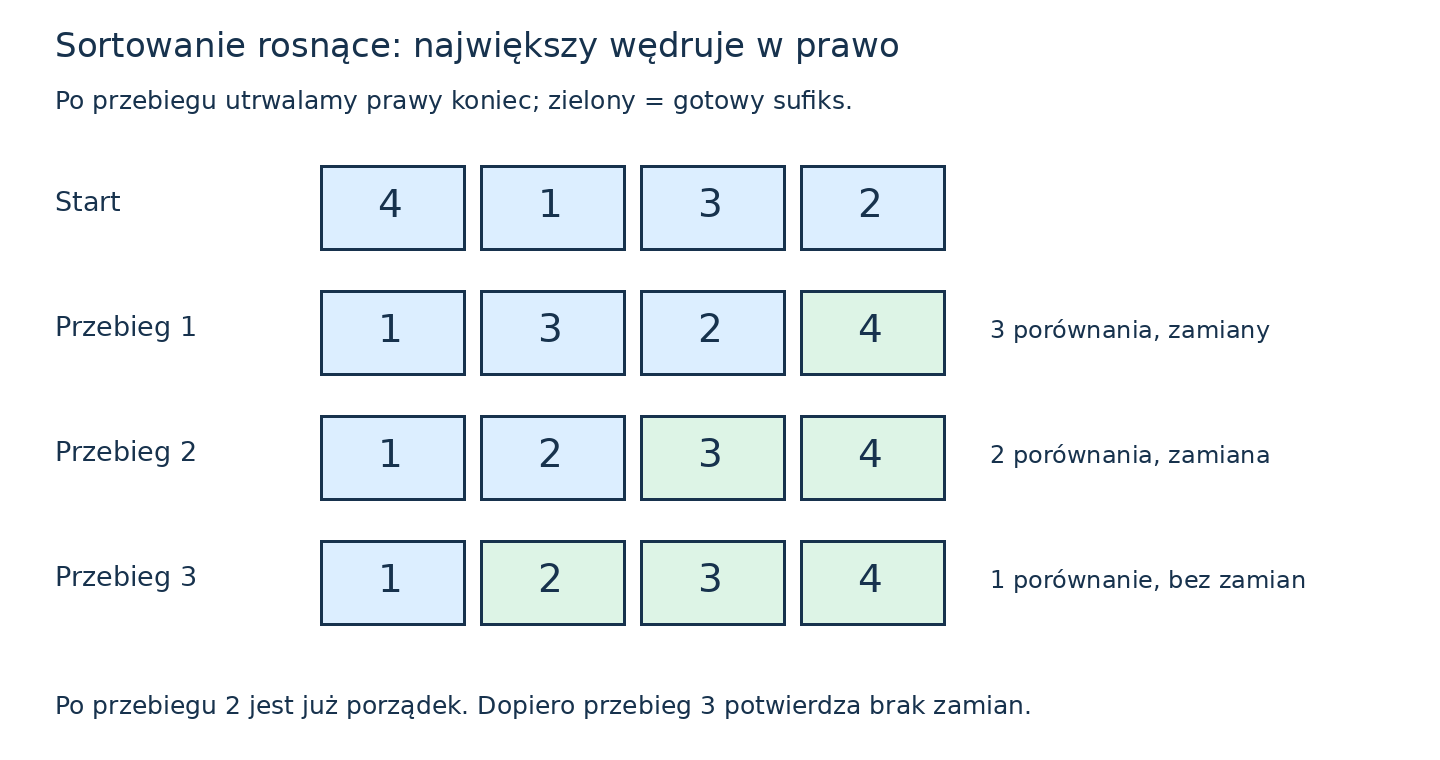

Kolejne przebiegi dla 4, 1, 3, 2. Porównujemy tylko część przed gotowym sufiksem. Przebieg bez zamian pozwala zakończyć pracę.

### Najpierw śledzimy przebiegi

W pierwszym przebiegu porównamy pary o indeksach `(0,1)`, `(1,2)` i `(2,3)`. Zamiana odbywa się od razu, więc następna para widzi już zmienione dane. Po nim największy element znajdzie się na końcu. W kolejnym przebiegu ten ostatni element zostawiamy w spokoju.

**Przewidź:** zapisz tablicę po każdej z trzech pierwszych par. Oczekuj kolejno `1,4,3,2`, `1,3,4,2`, `1,3,2,4`. Potem przewidź stan po drugim przebiegu. Czy algorytm od razu wie, że wszystko jest już posortowane?

Zmienna `end` jest ostatnim indeksem aktywnej części; warunek wewnętrzny `i < end` zapewnia poprawność `a[i + 1]`. Flaga `swapped` opisuje cały przebieg i jest zerowana przed rozpoczęciem następnego. Liczymy **porównania par elementów**, bez doliczania testów sterujących pętlami.

In [ ]:
#include <stdio.h>

int main(void)
{
    double a[4] = {4.0, 1.0, 3.0, 2.0};
    const int n = 4;
    int comparisons = 0;

    for (int end = n - 1; end > 0; --end) {
        int swapped = 0;
        for (int i = 0; i < end; ++i) {
            ++comparisons;
            if (a[i] > a[i + 1]) {
                double tmp = a[i];
                a[i] = a[i + 1];
                a[i + 1] = tmp;
                swapped = 1;
            }
        }
        printf("Przebieg %d: ", n - end);
        for (int i = 0; i < n; ++i) printf("%.0f ", a[i]);
        printf("| byla_zamiana=%d, porownan lacznie=%d\n", swapped, comparisons);
        if (!swapped) break;
    }
    return 0;
}

**Interpretacja:** stany zgadzają się z diagramem. Licznik narasta do 3, 5 i 6. `swapped` wynosi kolejno 1, 1 i 0: mówi, **czy wystąpiła choć jedna zamiana**, a nie ile było zamian. Po drugim przebiegu dane są już uporządkowane, lecz dopiero trzeci przebieg daje algorytmowi informację o braku zamian.

Niezmiennik z W5 pomaga zrozumieć skracanie pracy: przed następnym przebiegiem za indeksem `end` znajduje się gotowy sufiks największych elementów. Właśnie dlatego nie trzeba porównywać go ponownie. Zamiana zachowuje wszystkie wartości — zmienia tylko ich położenie.

**Zmień:** zastąp dane przez `1, 2, 3, 4`, a potem przez `4, 3, 2, 1`. Przewidź liczbę przebiegów i porównań: odpowiednio 1 i 3 przebiegi, 3 i 6 porównań. Sprawdź również cztery dwójki: żadne porównanie nie powinno prowadzić do zamiany.

**Kontrola:** co zepsułoby pozostawienie `swapped = 1` z poprzedniego przebiegu? Stracilibyśmy możliwość rozpoznania przebiegu bez zamian. A zmiana `i < end` na `i <= end`? W pierwszym przebiegu odczytalibyśmy element poza końcem tablicy. Tę błędną zmianę analizujemy bez uruchamiania.

### Wydzielamy funkcję i mierzymy pracę

Obie poniższe funkcje sortują rosnąco pierwsze `n` elementów i zwracają liczbę porównań `a[i] > a[i + 1]`. `bubble_sort` ma flagę i wcześniejsze wyjście; `bubble_sort_full` wykonuje wszystkie przebiegi. Dzięki jednakowej miarze możemy porównać dwa sposoby organizacji tej samej pracy.

**Kontrakt:** `0 <= n <= 50`, a dla `n > 0` wskaźnik prowadzi do co najmniej `n` zainicjalizowanych, skończonych `double` dostępnych do odczytu i zapisu. W tym zakresie licznik mieści się w `int`. Dla `n = 0` lub `1` obie funkcje wykonują zero porównań i niczego nie zmieniają. NaN pomijamy: jego porównania nie opisują zwykłego porządku liczb.

**Przewidź:** obie tablice są już uporządkowane. Czy obie funkcje wykonają tyle samo porównań? Czy wynik sortowania będzie inny?

In [ ]:
#include <stdio.h>

int bubble_sort(double a[], int n)
{
    int comparisons = 0;
    for (int end = n - 1; end > 0; --end) {
        int swapped = 0;
        for (int i = 0; i < end; ++i) {
            ++comparisons;
            if (a[i] > a[i + 1]) {
                double tmp = a[i];
                a[i] = a[i + 1];
                a[i + 1] = tmp;
                swapped = 1;
            }
        }
        if (!swapped) break;
    }
    return comparisons;
}

int bubble_sort_full(double a[], int n)
{
    int comparisons = 0;
    for (int end = n - 1; end > 0; --end) {
        for (int i = 0; i < end; ++i) {
            ++comparisons;
            if (a[i] > a[i + 1]) {
                double tmp = a[i];
                a[i] = a[i + 1];
                a[i + 1] = tmp;
            }
        }
    }
    return comparisons;
}

int main(void)
{
    double a[4] = {1.0, 2.0, 3.0, 4.0};
    double b[4] = {1.0, 2.0, 3.0, 4.0};
    int fast_count = bubble_sort(a, 4);
    int full_count = bubble_sort_full(b, 4);

    printf("Z flaga: %d, bez flagi: %d porownan\n", fast_count, full_count);
    for (int i = 0; i < 4; ++i) {
        printf("i=%d, z flaga=%.0f, bez flagi=%.0f\n", i, a[i], b[i]);
    }
    return 0;
}

**Interpretacja:** wariant z flagą wykonuje 3 porównania, a bez flagi 6. Wyniki obu są takie same: `1, 2, 3, 4`. Dla `n >= 2` wariant bez flagi zawsze porównuje `(n-1) + (n-2) + ... + 1 = n(n-1)/2` par, również gdy niczego nie trzeba zamieniać.

Mówimy, że ma **koszt kwadratowy**, `O(n²)`: przy wzroście rozmiaru zasadnicza część liczby porównań rośnie jak kwadrat `n`. Wariant z flagą w najgorszym przypadku też ma taki koszt. Dla uporządkowanych danych zatrzymuje się po `n-1` porównaniach, więc jego najlepszy przypadek jest liniowy, `O(n)`. Ściślej, liczby porównań w tych przypadkach rosną odpowiednio jak `Θ(n²)` i `Θ(n)`; zapis `O` podaje górne ograniczenie wzrostu. Nie jest to obietnica konkretnej liczby sekund ani model wszystkich kosztów komputera.

**Zmień:** do obu tablic wpisz `2, -1, 2, 0`. Przed uruchomieniem przewidź wynik `-1, 0, 2, 2`. Sprawdź, czy zachowaliśmy obie dwójki. Następnie wywołaj obie funkcje z `n = 1` i `n = 0`: liczniki powinny wynosić zero, a tablice pozostać bez zmian. Nie tworzymy tablicy zerowej długości; przekazujemy zero jako liczbę używanych miejsc istniejącej tablicy.

**Kontrola:** czy usunięcie flagi może zmienić uporządkowane wartości, czy przede wszystkim liczbę wykonanych operacji? Przy poprawnych granicach wynik pozostaje ten sam. Z kolei zastąpienie porównania `>` przez `<` zmieni kierunek sortowania. Wypróbuj tę zmianę w jednej wersji i uzasadnij otrzymany porządek.

Sortowanie bąbelkowe pozwala dokładnie zobaczyć porównanie, zamianę, pętlę i niezmiennik. Dla dużych zbiorów używa się wydajniejszych algorytmów; tutaj priorytetem jest zrozumienie i sprawdzenie każdego kroku.

## W7.8 — Jak zapisać wyniki?

**Problem:** po zakończeniu programu jego tablica znika. Jak zachować liczby do następnego uruchomienia?

Plik tekstowy pozwoli przechować dane poza pamięcią programu. `FILE *` opisuje dostęp do otwartego strumienia; `fopen` otwiera plik, `fprintf` zapisuje sformatowany tekst, `fscanf` odczytuje wartości, a `fclose` kończy pracę ze strumieniem. Format i typ argumentu nadal muszą do siebie pasować — tak jak przy `printf` i `scanf` z W3.

**Przewidź:** czym różnią się otwarcia w trybach `r`, `w` i `a`? W trzech krótkich doświadczeniach zapiszemy dane, dopiszemy wiersz i odczytamy liczby. Sprawdzimy również nieudany odczyt. Tryb `w` usuwa poprzednią zawartość, dlatego użyjemy wyraźnie nazwanych plików ćwiczeniowych w katalogu `w7_dane`, względem katalogu notebooka. Zanim użyjemy wyniku, sprawdzimy powodzenie otwarcia, liczbę odczytanych pól i wynik ważnych operacji zapisu oraz zamknięcia.

### Plik jest strumieniem z nazwą

`printf("%d\n", x)` kieruje tekst na standardowe wyjście. `fprintf(file, "%d\n", x)` używa tych samych reguł formatowania, ale pozwala wybrać otwarty strumień. `FILE *` nie jest wskaźnikiem do naszych pomiarów: biblioteka używa go do obsługi strumienia.

| Tryb `fopen` | Istniejący plik | Brak pliku |
|:--|:--|:--|
| `"r"` | Odczyt od początku | Otwarcie nie powiedzie się |
| `"w"` | Zawartość zostaje usunięta | Próba utworzenia pliku |
| `"a"` | Zapis na końcu | Próba utworzenia pliku |

Istnieją także tryby łączące odczyt i zapis, np. `r+`, `w+`, `a+`; nie potrzebujemy ich w dzisiejszych doświadczeniach.

Uruchamiaj notebook z katalogu `7/`. Dołączony katalog **`w7_dane/`** zawiera mały plik wejściowy i opis nazw. Programy zapisują wyłącznie pliki ćwiczeniowe `w7_demo_*.txt` w tym katalogu. Są przeznaczone do ponownego tworzenia; nie przechowuj w nich własnych ważnych danych. `fopen` nie tworzy brakujących katalogów.

### Zapis: ważny jest także koniec operacji

**Przewidź:** co zostanie w pliku po drugim uruchomieniu tego programu? Tryb `w` przygotuje ponownie trzy wiersze, zamiast dopisać trzy kolejne. Zapis sprawdzamy po wyniku `fprintf`, a `fclose` wywołujemy również wtedy, gdy zapis zgłosił błąd. Błąd może ujawnić się dopiero przy opróżnianiu bufora podczas zamykania.

In [ ]:
#include <stdio.h>

int main(void)
{
    FILE *file = fopen("w7_dane/w7_demo_zapis.txt", "w");
    if (file == NULL) {
        perror("Otwarcie do zapisu");
        return 1;
    }
    int failed = 0;
    if (fprintf(file, "%d\n%d\n%d\n", 3, 9, 5) < 0) {
        perror("Zapis");
        failed = 1;
    }
    if (fclose(file) != 0) {
        perror("Zamkniecie po zapisie");
        failed = 1;
    }
    if (failed) return 1;
    puts("Zapisano 3, 9, 5 w w7_dane/w7_demo_zapis.txt");
    return 0;
}

**Interpretacja:** na ekran trafia informacja o powodzeniu, a do pliku trzy liczby w osobnych wierszach. `fprintf` zwraca wartość ujemną przy błędzie. `fclose` zwraca zero przy powodzeniu; po jego wywołaniu nie używamy już tego strumienia, również gdy zamknięcie zgłosiło błąd.

**Zmień:** zastąp ostatnią liczbę 5 przez 7, uruchom i otwórz plik jako tekst. Czy pozostała w nim poprzednia piątka? Nie: tryb `w` usunął starą zawartość.

**Kontrola:** dlaczego nie wywołujemy `fprintf`, jeśli `fopen` zwróciło `NULL`? Nie uzyskaliśmy dostępu do strumienia. Czy samo powodzenie otwarcia dowodzi, że wszystkie dane zapiszą się poprawnie? Nie — dlatego sprawdzamy również zapis i zamknięcie.

### Dopisywanie: drugi zapis trafia na koniec

**Przewidź:** funkcja pomocnicza najpierw otworzy plik w trybie `w`, a potem w `a`. Jakie dwa wiersze otrzymamy? Program przygotowuje swój plik od początku przy każdym uruchomieniu, więc doświadczenie działa również bez uruchamiania poprzedniej komórki.

In [ ]:
#include <stdio.h>

int write_line(const char *mode, int value)
{
    FILE *file = fopen("w7_dane/w7_demo_dopisywanie.txt", mode);
    if (file == NULL) {
        perror("Otwarcie");
        return 1;
    }
    int failed = 0;
    if (fprintf(file, "%d\n", value) < 0) {
        perror("Zapis wiersza");
        failed = 1;
    }
    if (fclose(file) != 0) {
        perror("Zamkniecie");
        failed = 1;
    }
    return failed;
}

int main(void)
{
    if (write_line("w", 10) != 0) return 1;
    if (write_line("a", 20) != 0) return 1;
    puts("Plik zawiera dwa wiersze: 10 i 20.");
    return 0;
}

**Interpretacja:** drugi zapis zachowuje pierwszy wiersz, bo używa `a`. Funkcja zwraca status operacji, a `main` nie kontynuuje po błędzie. Nazwa trybu to krótki napis przekazany funkcji; nie musimy jeszcze pisać własnego przetwarzania tekstu.

**Zmień:** drugie wywołanie na `write_line("w", 20)`. Przewidź, czy w pliku pozostanie 10. Zostanie tylko 20. Przywróć `a`, a następnie dodaj trzecie wywołanie z liczbą 30 i kontrolą statusu.

**Kontrola:** czy ponowne uruchomienie oryginalnego programu powiększy plik o kolejne dwa wiersze? Nie: pierwsze wywołanie ponownie użyje `w`. Samo uruchomienie programu rozpoczynającego od `a` miałoby inne zachowanie.

### Odczyt: sprawdzamy przypisania, nie wywołania

Dołączony `w7_dane/przyklad.txt` zawiera trzy małe liczby: 3, 9, 5. Nie jest nadpisywany przez program. `fscanf` działa podobnie do `scanf`, lecz czyta z podanego pliku.

**Przewidź:** jakiego wyniku `fscanf` oczekujemy przy pojedynczym polu `%d`? Co oznacza 0, a co `EOF`? Zapis `%4d` ogranicza pole do czterech znaków: konwersja nie spróbuje utworzyć dowolnie dużego `int`. Tutaj odczytujemy prosty, znany plik; pełną kontrolę separatorów i dodatkowych danych dołożymy w programie integracyjnym.

In [ ]:
#include <stdio.h>

int main(void)
{
    FILE *file = fopen("w7_dane/przyklad.txt", "r");
    if (file == NULL) {
        perror("Otwarcie do odczytu");
        return 1;
    }
    int failed = 0;
    for (int i = 0; i < 3; ++i) {
        int value;
        int status = fscanf(file, "%4d", &value);
        if (status != 1) {
            if (ferror(file)) puts("Blad odczytu strumienia.");
            else if (status == EOF) puts("Za wczesny koniec pliku.");
            else puts("Nie dopasowano liczby.");
            failed = 1;
            break;
        }
        printf("Odczytano: %d\n", value);
    }
    if (fclose(file) != 0) {
        perror("Zamkniecie po odczycie");
        failed = 1;
    }
    return failed;
}

**Interpretacja:** trzy udane konwersje dają trzy wydruki. Liczbę wolno wykorzystać dopiero po wyniku 1. Przy wyniku 0 funkcja nie dopasowała pola; `EOF` oznacza koniec wejścia lub błąd przed pierwszą konwersją tego wywołania. `ferror` pozwala sprawdzić błąd strumienia.

**Zmień:** zrób kopię `przyklad.txt` o nazwie `w7_demo_proba.txt` w tym samym katalogu i ustaw tę nazwę w programie. Usuń z kopii ostatnią liczbę, potem w osobnej próbie zastąp drugą przez `kot`. Przewidź moment zatrzymania i komunikat. Oryginalny plik pozostaw jako wzorzec do następnych uruchomień.

**Kontrola:** czy trzy wywołania `fscanf` dowodzą odczytania trzech liczb? Nie: liczą się udane przypisania. Czy test `while (!feof(file))` zastępuje kontrolę wyniku odczytu? Nie — stan końca pojawia się dopiero po próbie odczytu, która go napotkała.

## W7.9 — Od danych do wyniku

**Problem:** czy potrafimy połączyć dzisiejsze kroki w jeden program, w którym każda część ma jasne zadanie?

Zaczniemy od jawnego przygotowania pliku ćwiczeniowego. Program przetwarzający odczyta liczbę pomiarów, sprawdzi pojemność, wczyta elementy, obliczy statystyki, posortuje tablicę i zapisze wynik do innego pliku. Błąd danych zatrzyma przetwarzanie przed użyciem nieodczytanego elementu. Oryginalne dane i zapisany wynik będą miały różne nazwy.

**Przewidź:** które informacje powinny pozostać takie same po sortowaniu — średnia, minimum, maksimum, a może kolejność? Sprawdzimy je na małym zestawie, który łatwo policzyć ręcznie. Potem zmienisz dane i sprawdzisz obsługę pustego lub niepełnego wejścia. Na koniec wybierzesz zadanie: zapis punktów sinusa, klasyfikację punktów względem okręgu albo zliczanie pomiarów powyżej i poniżej średniej. To różne zastosowania tej samej drogi od danych do wyniku.

### Ustalamy format, zanim napiszemy algorytm

Plik wejściowy zaczyna się od liczby pomiarów `n`, po której występuje dokładnie `n` liczb całkowitych. Białe znaki rozdzielają pola. Przyjmujemy `1 <= n <= 50` oraz pomiary od −999 do 999. Dzięki tym ograniczeniom prosta suma w `double` jest bezpieczna dla naszych danych. W pamięci użyjemy tablicy `double`, tak jak w funkcjach z wcześniejszych sekcji.

Pliki ćwiczeniowe to `w7_dane/w7_demo_wejscie.txt` i **inna nazwa wyniku**: `w7_dane/w7_demo_wynik.txt`. Najpierw przygotujemy dane programem poniżej. Ponowne przygotowanie przywraca punkt wyjścia, również po samodzielnych zmianach.

**Przewidź:** dla sześciu pomiarów `3, 9, 5, -1, 4, 4` oblicz średnią i wynik sortowania. Ile liczb jest ściśle poniżej średniej, ile ściśle powyżej, a ile jej równych?

In [ ]:
#include <stdio.h>

int main(void)
{
    FILE *file = fopen("w7_dane/w7_demo_wejscie.txt", "w");
    if (file == NULL) {
        perror("Przygotowanie wejscia");
        return 1;
    }
    int failed = 0;
    if (fprintf(file, "6\n3\n9\n5\n-1\n4\n4\n") < 0) {
        perror("Zapis wejscia");
        failed = 1;
    }
    if (fclose(file) != 0) {
        perror("Zamkniecie wejscia");
        failed = 1;
    }
    if (failed) return 1;
    puts("Przygotowano 6 pomiarow w w7_dane/w7_demo_wejscie.txt");
    return 0;
}

**Interpretacja przygotowania:** pierwsza szóstka oznacza liczbę pomiarów; sama nie jest pomiarem. Suma danych wynosi 24, średnia 4, a uporządkowane dane to `-1, 3, 4, 4, 5, 9`. Poniżej i powyżej średniej są po dwie liczby; dwie są jej równe.

### Mała osłona formatu, potem właściwe obliczenia

Sprawdzenie `value <= 999` po zwykłym `%d` nie zabezpiecza konwersji bardzo długiego tokenu. Pomocnicze `read_int` ogranicza pole przez `%4d` i próbuje odczytać następny znak przez `%c`. Cztery znaki dają co najwyżej 9999, mieszczące się nawet w minimalnym zakresie `int` wymaganym przez C. Następny znak musi być biały; dzięki temu `12345` nie zostanie przyjęte jako początek `1234`. Przy końcu pliku dopuszczamy ostatnią liczbę bez końcowej nowej linii.

Znamy już `%c` i liczbę przypisań z W3. `isspace` z `<ctype.h>` rozpoznaje białe znaki, również koniec wiersza Windows. Przekazujemy `(unsigned char)separator`, aby spełnić kontrakt tej funkcji. Po sprawdzeniu formatu `load_data` osobno sprawdza zakres liczby pomiarów i ich wartości oraz odrzuca nadmiarowe dane. To pomoc techniczna chroniąca wejście; samo liczenie i sortowanie pozostają oddzielnymi etapami.

Czytaj program od `main`: **wczytaj → oblicz → posortuj → zapisz**. Funkcje pomocnicze są zdefiniowane wcześniej, więc kompilator zna je przed wywołaniem. `load_data` i `save_result` zwracają 0 przy powodzeniu, 1 przy błędzie. Długość wyjściowa jest zapisywana dopiero po pełnym powodzeniu odczytu i zamknięcia.

**Przewidź:** czy plik wynikowy powinien być otwierany, jeśli brakuje jednego z zadeklarowanych pomiarów? Nie: najpierw musimy mieć kompletny poprawny zestaw. Uruchom program po przygotowaniu wejścia.

In [ ]:
#include <stdio.h>
#include <ctype.h>
#define MAX_SIZE 50

int read_int(FILE *file, int *value)
{
    int parsed;
    char separator;
    int status = fscanf(file, "%4d%c", &parsed, &separator);
    if (status == 2 && isspace((unsigned char)separator)) {
        *value = parsed;
        return 1;
    }
    if (status == 1 && feof(file) && !ferror(file)) {
        *value = parsed;
        return 1;
    }
    return 0;
}

int load_data(const char *path, double a[], int capacity, int *count)
{
    FILE *file = fopen(path, "r");
    if (file == NULL) {
        perror("Otwarcie wejscia");
        return 1;
    }
    int n = 0;
    int failed = 0;
    if (!read_int(file, &n) || n < 1 || n > capacity) failed = 1;
    for (int i = 0; !failed && i < n; ++i) {
        int value;
        if (!read_int(file, &value) || value < -999 || value > 999) {
            failed = 1;
        } else {
            a[i] = value;
        }
    }
    if (!failed) {
        char extra;
        if (fscanf(file, " %c", &extra) != EOF || ferror(file)) failed = 1;
    }
    if (fclose(file) != 0) failed = 1;
    if (failed) {
        puts("Blad: format, zakres, liczba danych lub odczyt pliku.");
        return 1;
    }
    *count = n;
    return 0;
}

int average(const double *a, int n, double *result)
{
    if (n <= 0) return 0;
    double sum = 0.0;
    for (int i = 0; i < n; ++i) sum += a[i];
    *result = sum / n;
    return 1;
}

int bubble_sort(double a[], int n)
{
    int comparisons = 0;
    for (int end = n - 1; end > 0; --end) {
        int swapped = 0;
        for (int i = 0; i < end; ++i) {
            ++comparisons;
            if (a[i] > a[i + 1]) {
                double tmp = a[i];
                a[i] = a[i + 1];
                a[i + 1] = tmp;
                swapped = 1;
            }
        }
        if (!swapped) break;
    }
    return comparisons;
}

int save_result(const char *path, const double *a, int n)
{
    FILE *file = fopen(path, "w");
    if (file == NULL) {
        perror("Otwarcie wyniku");
        return 1;
    }
    int failed = fprintf(file, "%d\n", n) < 0;
    for (int i = 0; !failed && i < n; ++i) {
        if (fprintf(file, "%.0f\n", a[i]) < 0) failed = 1;
    }
    if (fclose(file) != 0) failed = 1;
    if (failed) puts("Blad zapisu lub zamkniecia wyniku.");
    return failed;
}

int main(void)
{
    double tab[MAX_SIZE];
    int n = 0;
    double mean = 0.0;
    if (load_data("w7_dane/w7_demo_wejscie.txt", tab, MAX_SIZE, &n) != 0) return 1;
    if (!average(tab, n, &mean)) return 1;
    int below = 0, above = 0;
    for (int i = 0; i < n; ++i) {
        if (tab[i] < mean) ++below;
        if (tab[i] > mean) ++above;
    }
    bubble_sort(tab, n);
    printf("n=%d, srednia=%.2f, min=%.0f, max=%.0f\n",
           n, mean, tab[0], tab[n - 1]);
    printf("Ponizej=%d, powyzej=%d, rowne=%d\n", below, above, n - below - above);
    if (save_result("w7_dane/w7_demo_wynik.txt", tab, n) != 0) return 1;
    puts("Zapisano uporzadkowane dane do w7_dane/w7_demo_wynik.txt");
    return 0;
}

**Interpretacja:** wyniki na ekranie zgadzają się z ręcznym rachunkiem. Po sortowaniu pierwszy i ostatni element dają minimum i maksimum. Średnia oraz liczby pomiarów poniżej i powyżej niej zostały obliczone przed zmianą kolejności. Plik wynikowy zawiera najpierw 6, a potem sześć uporządkowanych pomiarów. Ma ten sam format liczbowy co wejście, więc można go ponownie wczytać.

**Kontrakty pomocników:** `load_data` otrzymuje pojemność od 1 do 50, tablicę co najmniej tej pojemności i osobny obiekt `int` na liczbę danych. Po błędzie część elementów mogła już zostać zapisana — nie używamy ich jako poprawnego zestawu; `count` pozostaje bez zmian. `save_result` otrzymuje od 1 do 50 odczytywalnych, całkowitych wartości `double` z zakresu `[-999,999]`; format `%.0f` zachowuje je bez części ułamkowej. `average` i `bubble_sort` mają te same kontrakty co wcześniej. Wyjście nie podmienia wejścia, a ponowne przetwarzanie tego samego wejścia odtwarza ten sam wynik.

**Zmień:** po przygotowaniu pliku zmodyfikuj wyłącznie `w7_demo_wejscie.txt`, a następnie uruchom sam program integracyjny:

| Próba | Oczekiwanie |
|:--|:--|
| `1` i jeden pomiar `-7` | Średnia, minimum i maksimum −7; zero liczb poniżej i powyżej |
| `3` i pomiary `2, 2, 2` | Trzy równe średniej; wszystkie powtórzenia zachowane |
| `0`, `-1` albo `51` jako `n` | Odrzucenie liczby pomiarów |
| Brak ostatniego pomiaru, `kot`, `1.5` albo `1000` jako pomiar | Odrzucenie wejścia |
| Poprawne dane i dodatkowa liczba na końcu | Odrzucenie nadmiarowych danych |
| Bardzo długi ciąg cyfr zamiast pola | Odrzucenie przez ograniczenie szerokości i separatora |

Po błędzie odczytu program nie tworzy nowego wyniku. **Poprzedni plik wynikowy może nadal istnieć**: jego obecność nie dowodzi powodzenia ostatniej próby. Sprawdzaj komunikat i status programu. Aby wrócić do wzorca, uruchom ponownie komórkę przygotowującą dane. Aby sprawdzić brak pliku, tymczasowo zmień nazwę wejścia w `main` na nieistniejącą i przywróć ją po próbie.

**Kontrola:** dlaczego nie otwieramy wyniku przed zakończeniem odczytu? Błąd wejścia nie powinien usuwać poprzedniej zawartości wyniku przez przedwczesne `w`. Dlaczego nie łączymy błędu `fprintf` i `fclose` w wyrażeniu z `||`? Krótkie spięcie mogłoby pominąć zamknięcie. Kontrolujemy je oddzielnie.

### Wybierz kolejne doświadczenie

**A — sinus do wykresu.** Dla `n = 9` zapisz pary `x, sin(x)` w `[0, 2π]`, włącznie z końcami. Użyj `pi = acos(-1.0)`, kroku `h = 2*pi/(n-1)` i `x = i*h`; wymagaj `n >= 2`. Wykorzystaj `<math.h>` oraz `-lm` przy linkowaniu (w kernelu C: `//%ldflags:-lm`). Przed uruchomieniem przewidź liczbę wierszy. Po zapisie sprawdź próbki przy `0`, `π/2`, `π`, `3π/2` i `2π`: wartości powinny być bliskie `0, 1, 0, -1, 0`, z uwzględnieniem zaokrągleń. Zmień `n` na 17 i wyjaśnij, dlaczego zakres się nie zmienia. Wykres utwórz w znanym Ci narzędziu.

**B — punkty w okręgu.** Przygotuj plik z parami współrzędnych i czytaj je dwiema kontrolowanymi konwersjami. Dla małych skończonych współrzędnych sprawdzaj `x*x + y*y < 1.0`. To wnętrze koła o środku `(0,0)` i promieniu 1; brzeg jest wykluczony. Zanim napiszesz program, sklasyfikuj `(0,0)`, `(0.5,0.5)`, `(1,0)` i `(2,0)` — oczekuj dwóch punktów wewnątrz. Zmień `<` na `<=` i uzasadnij nową liczbę 3. Po częściowym odczycie pary nie używaj żadnej pary jako kompletnej. Tu wystarczy mały, przygotowany plik o uzgodnionym zakresie; bezpieczna konwersja dowolnego tekstu zmiennoprzecinkowego to dalszy temat.

**C — losowe pomiary.** Wygeneruj do 50 danych w `[-5,5]` przy stałym ziarnie, zapisz je z wystarczającą precyzją do osobnego pliku ćwiczeniowego, wczytaj i policz średnią oraz liczby elementów ściśle poniżej i powyżej niej. To wariant z danymi zmiennoprzecinkowymi — nie przekazuj ułamków do dzisiejszego czytnika liczb całkowitych. Możesz najpierw wykonać część obliczeniową wyłącznie w tablicy. Sprawdź, że `poniżej + powyżej + równe == n`; dla samych dwójek oczekuj `0 + 0 + n`. Powtórz próbę z tym samym ziarnem, potem zmień ziarno i wyjaśnij różnicę między powtarzalnością a jakością losowania.

W każdym zadaniu wybierz nową nazwę z prefiksem `w7_demo_` w `w7_dane`, kontroluj otwarcie, każdą wymaganą konwersję, ważne zapisy i zamknięcie. Nie zwiększaj pojemności przez niekontrolowane `n` i nie nadpisuj danych wzorcowych.

### Sprawdź, co umiesz wyjaśnić

1. Jakie indeksy są poprawne dla `double a[5]`? Czy `a[5]` musi wywołać awarię?
2. Dlaczego `sizeof a / sizeof a[0]` liczy elementy przy rzeczywistej tablicy, a nie przy parametrze wskaźnikowym?
3. Który obiekt zmienia `p = a + 1`, a który `p[0] = 7`?
4. Co musi wiedzieć wywołujący przed `fill(a + 3, n)`?
5. Dlaczego stałe ziarno pomaga przy szukaniu błędu? Czy `rand()/RAND_MAX` daje zwykle ułamek?
6. Który wariant bubble sort może rozpoznać już posortowane dane po jednym przebiegu?
7. Dlaczego po błędzie `fscanf` nie można użyć niewczytanej wartości? Kiedy trzeba sprawdzić `fclose`?
8. Jak odróżnisz brak poprawnego wyniku od pozostawionego pliku z poprzedniej udanej próby?

<details>
<summary>Odpowiedzi — zajrzyj po własnej próbie</summary>

1. Indeksy `0..4`. Dostęp `a[5]` oznacza niezdefiniowane zachowanie, bez gwarancji wyniku ani awarii.
2. Przy tablicy dzielimy rozmiar całości przez rozmiar elementu. Przy wskaźniku znamy tylko rozmiar obiektu wskaźnika; długość trzeba przekazać osobno.
3. Pierwsze przypisanie zmienia wartość wskaźnika `p`; drugie zmienia element tablicy pod jego aktualnym adresem.
4. Musi zapewnić dostęp do co najmniej `n` elementów od nowego początku, poprawną długość i prawo zapisu.
5. To samo ziarno odtwarza sekwencję w tej samej implementacji. Dzielenie dwóch `int` odrzuca ułamek; rzutujemy operand przed dzieleniem.
6. Wersja z flagą braku zamian. Wersja wykonująca wszystkie przebiegi nadal ma kwadratową liczbę porównań.
7. Nieudana konwersja nie ustaliła potrzebnej wartości. Wynik `fclose` sprawdzamy także po odczycie, a po zapisie może on ujawnić opóźniony błąd; zamknięcie wykonujemy również po wcześniejszym błędzie zapisu.
8. Sprawdzamy status i komunikat ostatniego uruchomienia. Sam istniejący plik nie potwierdza aktualnego powodzenia.

</details>

Potrafisz teraz połączyć pętlę, poprawny wskaźnik i tablicę o znanej pojemności. Sprawdzenie danych poprzedza obliczenia, a zapis wyniku wymaga potwierdzenia powodzenia. W W8 wrócimy szerzej do przetwarzania danych z plików.